In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
import math

In [2]:
# Load World Happiness data (2019)
happiness_df = pd.read_csv("../../data/raw/2019.csv")

# Structural overview
print(f"Dataset shape: {happiness_df.shape}")
print("-" * 50)
happiness_df.info()

Dataset shape: (156, 9)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [3]:
happiness_df.isnull().sum()

Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
dtype: int64

In [4]:
display(happiness_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Overall rank,156.0,78.500000,45.177428,1.000,39.75000,78.5000,117.25000,156.000
Score,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769
GDP per capita,156.0,0.905147,0.398389,0.000,0.60275,0.9600,1.23250,1.684
Social support,156.0,1.208814,0.299191,0.000,1.05575,1.2715,1.45250,1.624
Healthy life expectancy,156.0,0.725244,0.242124,0.000,0.54775,0.7890,0.88175,1.141
Freedom to make life choices,156.0,0.392571,0.143289,0.000,0.30800,0.4170,0.50725,0.631
Generosity,156.0,0.184846,0.095254,0.000,0.10875,0.1775,0.24825,0.566
Perceptions of corruption,156.0,0.110603,0.094538,0.000,0.04700,0.0855,0.14125,0.453


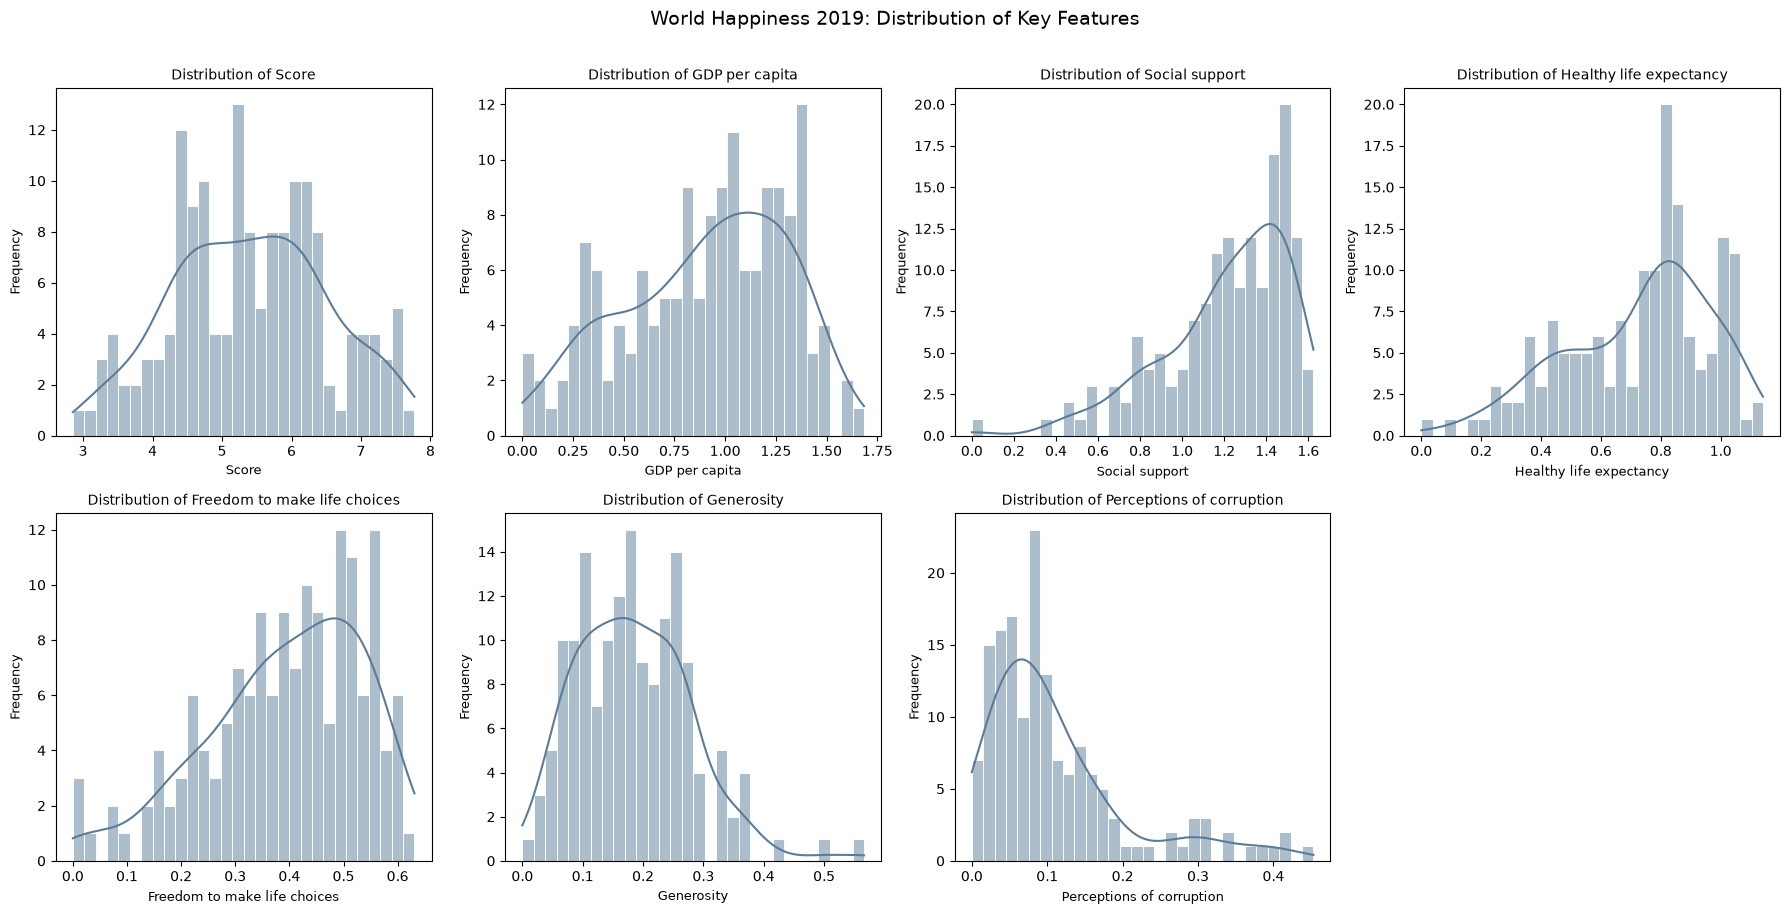

In [5]:

# 1. Auto-detect numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 2. Drop useless columns for 2019
cols_to_exclude = ['Overall rank']
clean_cols = [c for c in numeric_cols if c not in cols_to_exclude]

# 3. Calculate grid size
n = len(clean_cols) # n = 7
ncols = 4
nrows = math.ceil(n / ncols)

# 4. Create figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# 5. Plot distributions
for i, feature in enumerate(clean_cols):
    sns.histplot(
        happiness_df[feature].dropna(),
        bins=30,
        kde=True,
        ax=axes[i],
        color="#5b7c99",
        edgecolor="white"
    )
    axes[i].set_title(f"Distribution of {feature}", fontsize=10)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# 6. Hide unused subplots
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2019: Distribution of Key Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

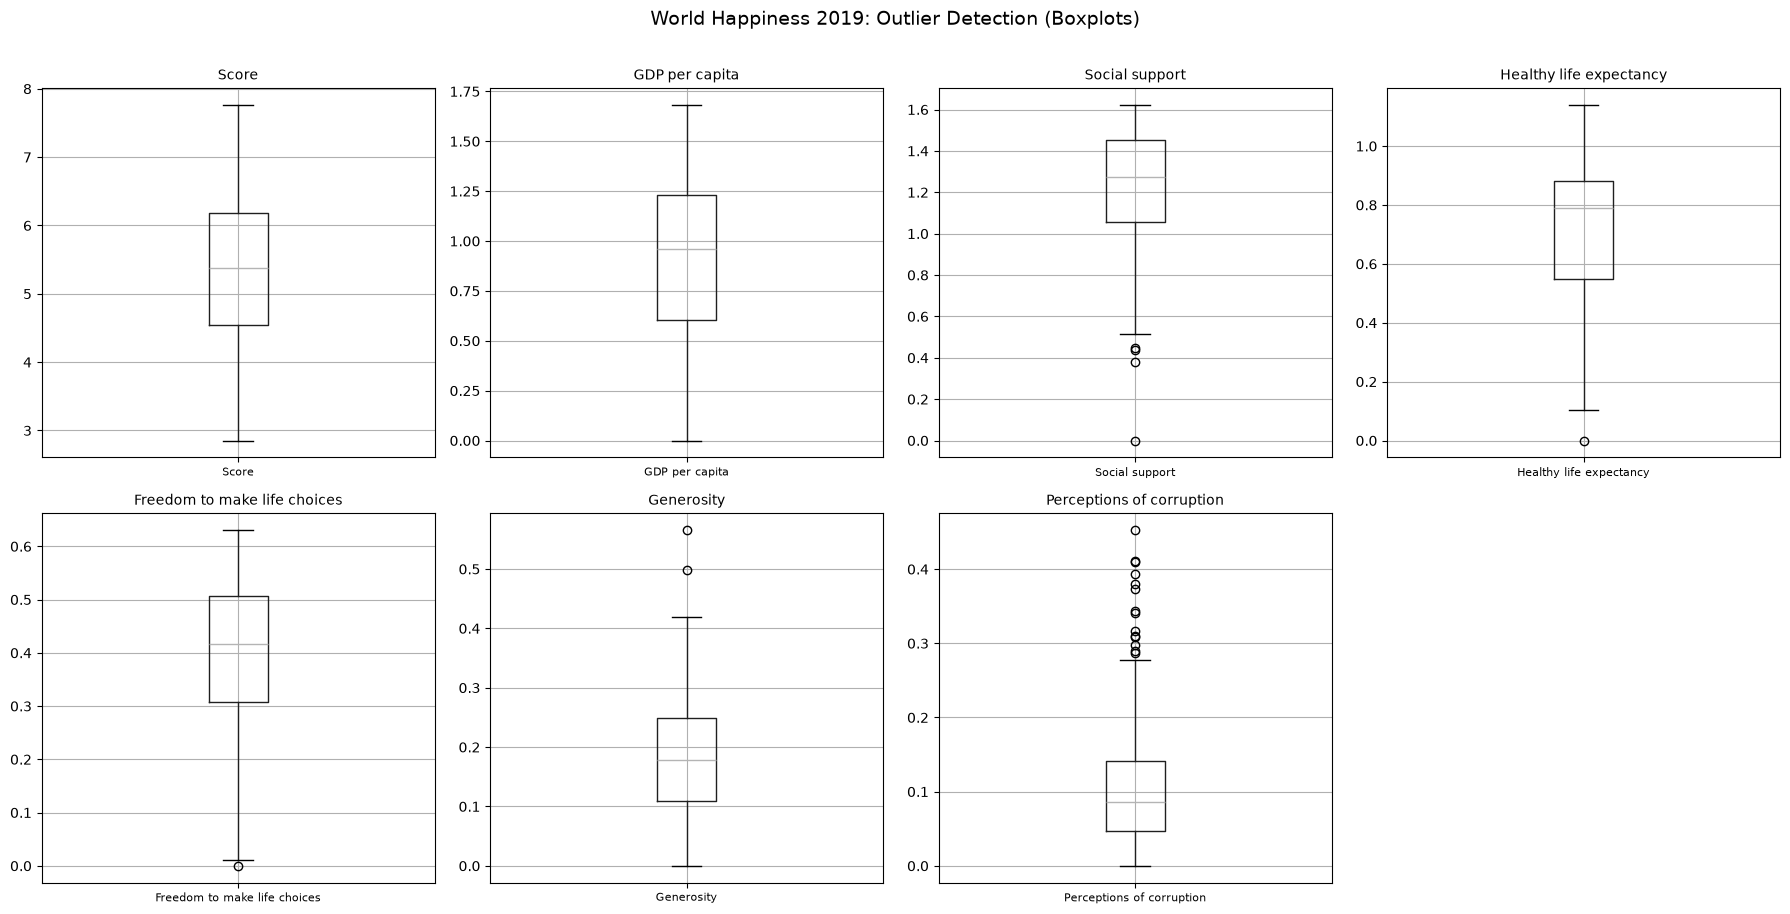

In [6]:
# Calculate grid size
n = len(clean_cols)
ncols = 4
nrows = math.ceil(n / ncols)

# Create figure
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
axes = axes.flatten()

# Plot boxplots
for i, col in enumerate(clean_cols):
    happiness_df.boxplot(column=col, ax=axes[i], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", labelsize=8)

# Hide unused subplots
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("World Happiness 2019: Outlier Detection (Boxplots)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [7]:


def get_outliers(df, column_name):
    # 1. Calcular el primer cuartil (25%) y el tercer cuartil (75%)
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    
    # 2. Calcular el Rango Intercuartílico (IQR)
    IQR = Q3 - Q1
    
    # 3. Calcular los límites (bigotes)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # 4. Filtrar los países que se salen de esos límites
    outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]
    
    # 5. Ordenar por el valor de la columna para verlos fácil
    outliers = outliers[['Country or region', 'Score', column_name]].sort_values(by=column_name)
    
    print(f"--- Outliers para {column_name} ---")
    print(f"Límite inferior: {lower_bound:.2f} | Límite superior: {upper_bound:.2f}")
    print(f"Total de outliers encontrados: {len(outliers)}")
    print("-" * 50)
    print(outliers.to_string(index=False))

# Ejecutar la función para 'Social support' en 2019
get_outliers(happiness_df, 'Social support')

--- Outliers para Social support ---
Límite inferior: 0.46 | Límite superior: 2.05
Total de outliers encontrados: 4
--------------------------------------------------
       Country or region  Score  Social support
Central African Republic  3.083           0.000
                   Syria  3.462           0.378
                   Benin  4.883           0.437
                 Burundi  3.775           0.447


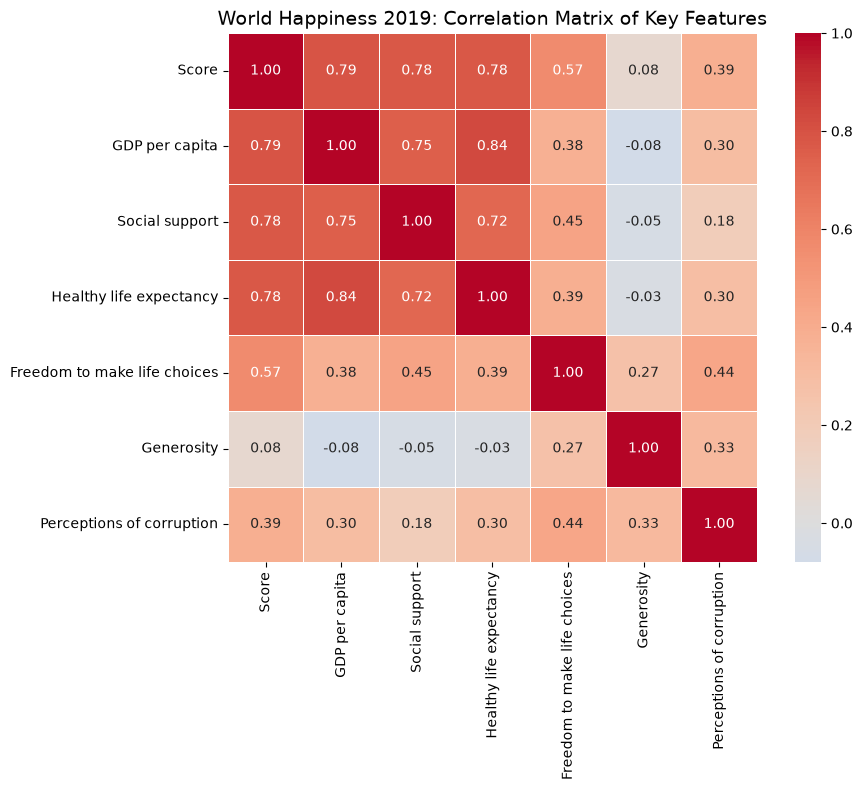

In [8]:
# Calculate correlation matrix
corr = happiness_df[clean_cols].corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    center=0, 
    ax=ax, 
    square=True,
    linewidths=0.5
)

ax.set_title("World Happiness 2019: Correlation Matrix of Key Features", fontsize=14)
plt.tight_layout()
plt.show()